# Formative 2 – HMM for phone activity data

I collected accel + gyro with Sensor Logger and trained a Gaussian HMM in NumPy (no hmmlearn).
States: standing, walking, jumping, still.

Training uses Baum-Welch (stop when log-likelihood barely moves). Decoding uses Viterbi so I can compute sensitivity / specificity / accuracy on held-out files.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from data_utils import (
    ACTIVITY_TO_ID,
    ID_TO_ACTIVITY,
    load_dataset,
    load_recording,
    prepare_xy,
    estimate_sampling_rate,
    resample_dataframe,
)
from features import FEATURE_NAMES
from hmm import GaussianHMM
from metrics import confusion_matrix, per_class_sensitivity_specificity

sns.set_theme(style="whitegrid", context="notebook")
STATE_NAMES = [ID_TO_ACTIVITY[i] for i in range(4)]
print("Project root:", ROOT)
print("States:", STATE_NAMES)
print("Features:", FEATURE_NAMES)

Project root: C:\Users\PC\Documents\hmm-human-activity-recognition
States: ['standing', 'walking', 'jumping', 'still']
Features: ['mean_acc_mag', 'var_acc_mag', 'std_acc_mag', 'sma_acc', 'rms_acc', 'corr_xy', 'mean_gyro_mag', 'std_gyro_mag', 'dominant_freq', 'spectral_energy']


## 1. Sampling rate and windows

My phone logged near 100 Hz. I resample everything to 50 Hz so the windows stay the same length.

- window = 1.0 s (50 samples) → about 1 Hz FFT resolution, enough to tell walking cadence from near-zero still/standing
- hop = 0.5 s so consecutive windows overlap a bit

Sampling rate used for this project is in the cell below.

In [ ]:
TARGET_FS = 50.0   # resample target
WINDOW_SEC = 1.0
HOP_SEC = 0.5

# from Sensor Logger Metadata on my SM-A325N
SAMPLING_RATES = {
    "Emmanuel Nsabagasa (SM-A325N)": "~100 Hz (sampleRateMs=10), then resampled to 50 Hz",
}
display(pd.DataFrame(
    [{"Person / phone": k, "Sampling rate": v} for k, v in SAMPLING_RATES.items()]
))

,Member,Sampling rate
0,Device SM-A325N (Android Sensor Logger),~100 Hz (sampleRateMs=10); resampled to 50 Hz


## 2. Load recordings

Training CSVs are under `data/raw/<activity>/`. Held-out files are under `data/test/<activity>/`.
Columns after import: timestamp + accel xyz + gyro xyz.

In [3]:
train_X_raw, train_y_raw, train_meta = load_dataset(
    ROOT / "data" / "raw",
    target_fs=TARGET_FS,
    window_sec=WINDOW_SEC,
    hop_sec=HOP_SEC,
)
test_X_raw, test_y_raw, test_meta = load_dataset(
    ROOT / "data" / "test",
    target_fs=TARGET_FS,
    window_sec=WINDOW_SEC,
    hop_sec=HOP_SEC,
)

meta_df = pd.DataFrame(train_meta + test_meta)
print(f"Train files: {len(train_meta)} | Test files: {len(test_meta)}")
print(f"Train windows: {sum(len(y) for y in train_y_raw)} | Test windows: {sum(len(y) for y in test_y_raw)}")
display(meta_df.groupby("activity").agg(
    n_files=("file", "count"),
    mean_native_fs=("native_fs_hz", "mean"),
    total_windows=("n_windows", "sum"),
).round(2))

Train files: 80 | Test files: 8
Train windows: 1224 | Test windows: 120


,n_files,mean_native_fs,total_windows
activity,,,
jumping,22,99.9,323
standing,22,99.9,353
still,22,99.9,331
walking,22,99.9,337


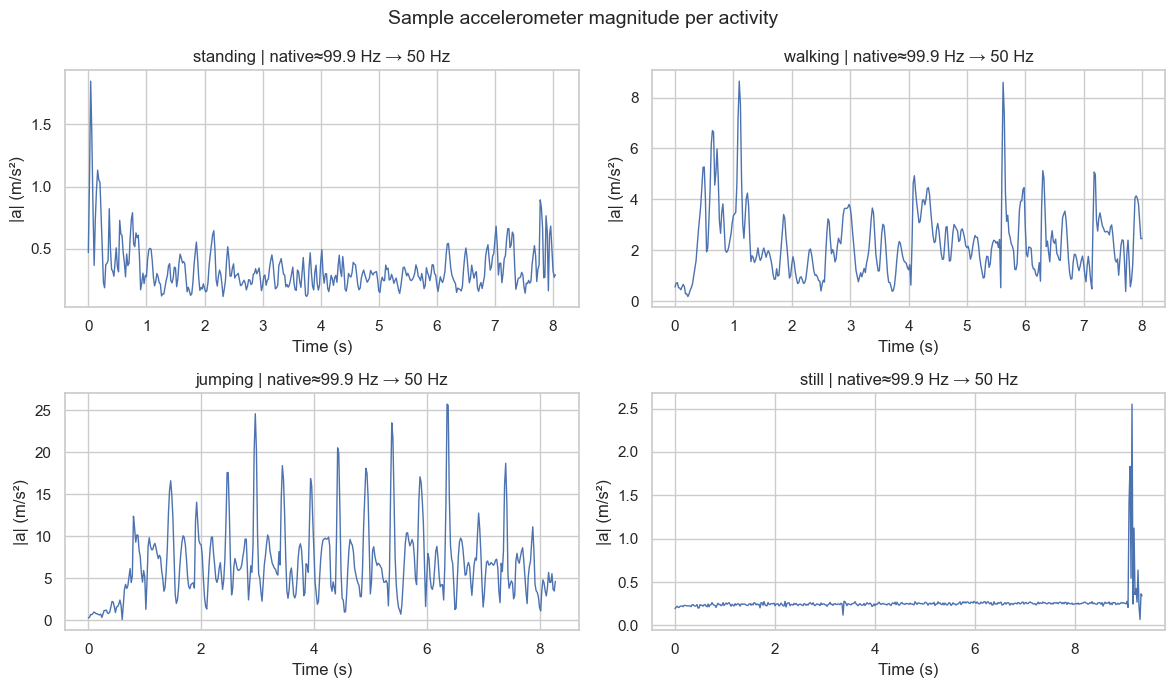

In [4]:
# one example file per activity
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=False)
axes = axes.ravel()

for ax, activity in zip(axes, STATE_NAMES):
    folder = ROOT / "data" / "raw" / activity
    files = sorted(folder.glob("*.csv"))
    if not files:
        ax.set_title(f"{activity}: no files")
        continue
    df = load_recording(files[0])
    fs = estimate_sampling_rate(df["timestamp"].to_numpy())
    df = resample_dataframe(df, TARGET_FS)
    mag = np.sqrt(df["acc_x"]**2 + df["acc_y"]**2 + df["acc_z"]**2)
    ax.plot(df["timestamp"], mag, lw=1.0)
    ax.set_title(f"{activity} | native≈{fs:.1f} Hz → {TARGET_FS:.0f} Hz")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("|a| (m/s²)")

fig.suptitle("Sample accelerometer magnitude per activity", fontsize=14)
fig.tight_layout()
plt.show()

## 3. Features

Time side: mean, variance, std, RMS, SMA of accel magnitude, xy correlation, gyro magnitude mean/std. Those mostly measure how strong/shaky the motion is.

Frequency side (FFT on accel magnitude): dominant frequency and spectral energy, so walking/jumping can show a clearer beat than still.

I Z-score using training mean/std only (then apply the same to test). Otherwise Hz and m/s^2 would swamp the Gaussians.

In [5]:
X_train, y_train, feat_mean, feat_std, train_seqs, train_labs = prepare_xy(
    train_X_raw, train_y_raw
)
X_test, y_test, _, _, test_seqs, test_labs = prepare_xy(
    test_X_raw, test_y_raw, mean=feat_mean, std=feat_std
)

print("Feature matrix (train):", X_train.shape)
display(pd.DataFrame(X_train, columns=FEATURE_NAMES).describe().round(3))

Feature matrix (train): (1224, 10)


,mean_acc_mag,var_acc_mag,std_acc_mag,sma_acc,rms_acc,corr_xy,mean_gyro_mag,std_gyro_mag,dominant_freq,spectral_energy
count,1224.000,1224.000,1224.000,1224.000,1224.000,1224.000,1224.000,1224.000,1224.000,1224.000
mean,0.000,0.000,-0.000,0.000,-0.000,-0.000,0.000,-0.000,0.000,0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,-0.705,-0.459,-0.730,-0.723,-0.710,-1.892,-0.888,-0.843,-0.892,-0.459
25%,-0.692,-0.459,-0.704,-0.693,-0.698,-0.839,-0.856,-0.811,-0.698,-0.459
50%,-0.632,-0.455,-0.609,-0.631,-0.633,0.048,-0.612,-0.529,-0.312,-0.455
75%,0.088,-0.164,0.260,0.132,0.146,0.772,0.895,0.723,0.268,-0.164
max,3.624,8.678,4.800,3.937,3.825,2.343,3.914,4.859,3.747,8.675


## 4. HMM pieces

- states Z: standing, walking, jumping, still
- observations X: feature vector per window (Z-scored)
- A: transition probs between activities
- B: diagonal Gaussian emission per state
- pi: start probabilities

## 5. Train (Baum-Welch)

I initialise means/variances from the labelled windows, then run Baum-Welch until the average log-likelihood change is under 1e-4.

Iter 001 | avg log-likelihood = 86.998801


Iter 002 | avg log-likelihood = 89.643183


Iter 003 | avg log-likelihood = 90.674026


Iter 004 | avg log-likelihood = 91.209238
Iter 005 | avg log-likelihood = 91.213021


Iter 006 | avg log-likelihood = 91.217181


Iter 007 | avg log-likelihood = 91.227146


Iter 008 | avg log-likelihood = 91.243657


Iter 009 | avg log-likelihood = 91.247447


Iter 010 | avg log-likelihood = 91.247487
Converged at iteration 10 (|dll| < 0.0001)


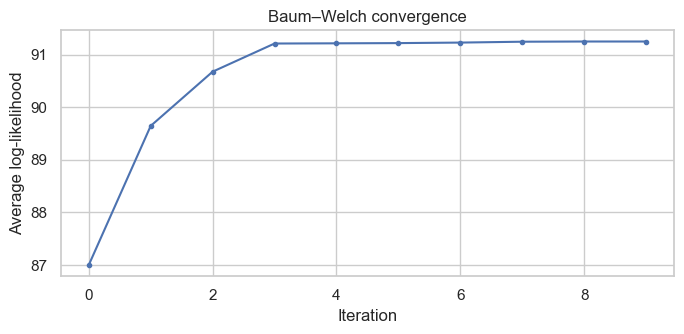

π = [0.2   0.325 0.225 0.25 ]
A =
 [[0.997 0.003 0.    0.   ]
 [0.013 0.973 0.013 0.   ]
 [0.    0.007 0.993 0.   ]
 [0.    0.    0.    1.   ]]


In [6]:
model = GaussianHMM(
    n_states=4,
    n_features=X_train.shape[1],
    state_names=STATE_NAMES,
    random_state=42,
)

# warm-start from labels, then EM on each file sequence
model.initialize(X_train, y_train)
model.fit(
    sequences=train_seqs,
    max_iter=80,
    tol=1e-4,
    verbose=True,
)

plt.figure(figsize=(7, 3.5))
plt.plot(model.log_likelihoods_, marker="o", ms=3)
plt.xlabel("Iteration")
plt.ylabel("Average log-likelihood")
plt.title("Baum–Welch convergence")
plt.tight_layout()
plt.show()

print("π =", np.round(model.pi, 3))
print("A =\n", np.round(model.A, 3))

## 6. Plots for A and emissions

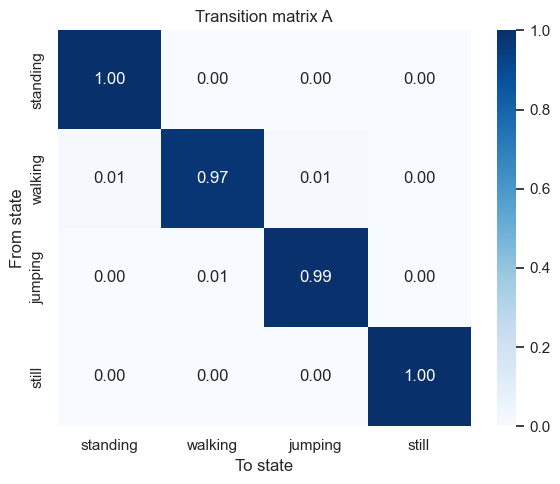

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    model.A,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=STATE_NAMES,
    yticklabels=STATE_NAMES,
    ax=ax,
    vmin=0,
    vmax=1,
)
ax.set_xlabel("To state")
ax.set_ylabel("From state")
ax.set_title("Transition matrix A")
plt.tight_layout()
plt.show()

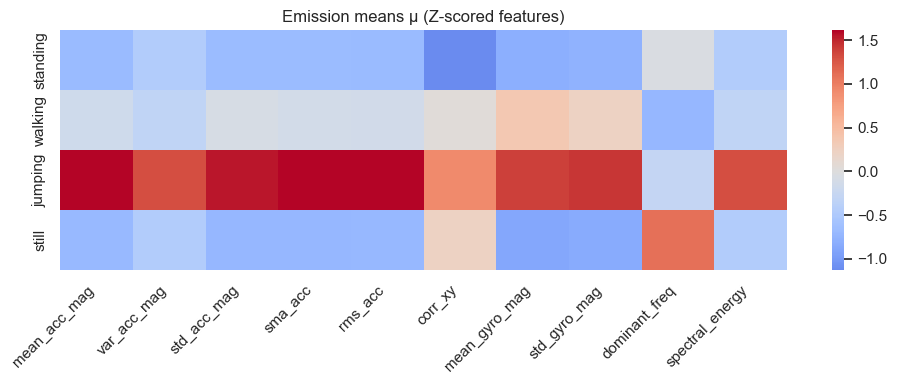

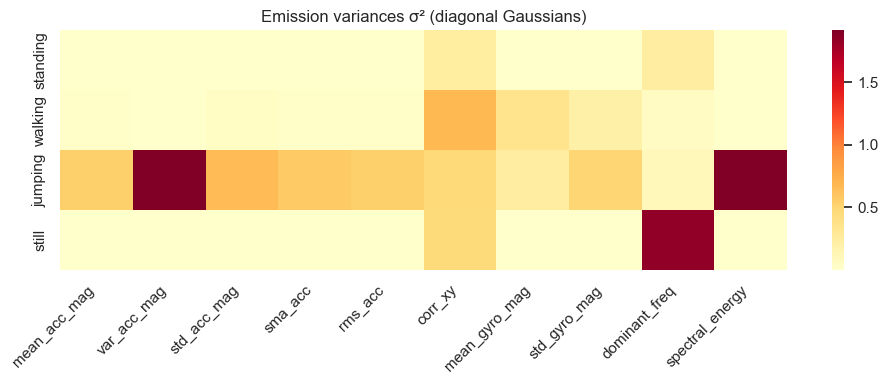

In [8]:
# emission means / variances
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(
    model.means,
    annot=False,
    cmap="coolwarm",
    center=0,
    yticklabels=STATE_NAMES,
    xticklabels=FEATURE_NAMES,
    ax=ax,
)
ax.set_title("Emission means μ (Z-scored features)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(
    model.vars,
    annot=False,
    cmap="YlOrRd",
    yticklabels=STATE_NAMES,
    xticklabels=FEATURE_NAMES,
    ax=ax,
)
ax.set_title("Emission variances σ² (diagonal Gaussians)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 7. Viterbi paths

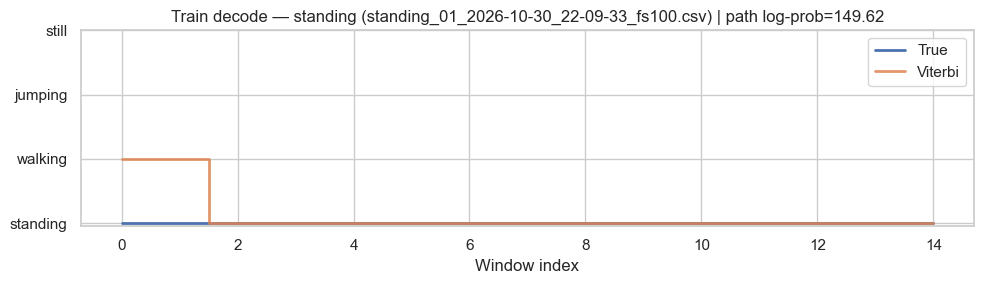

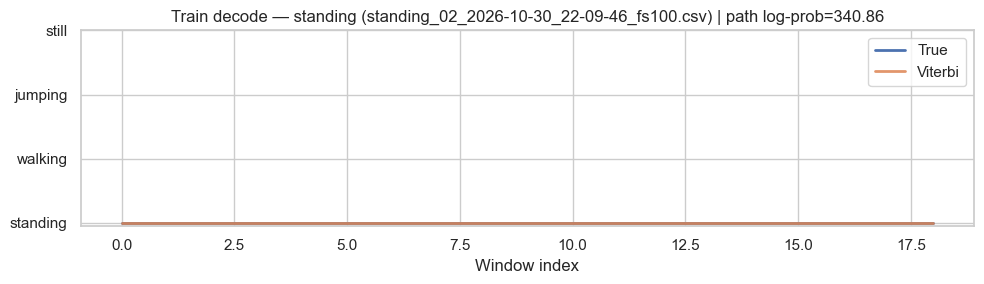

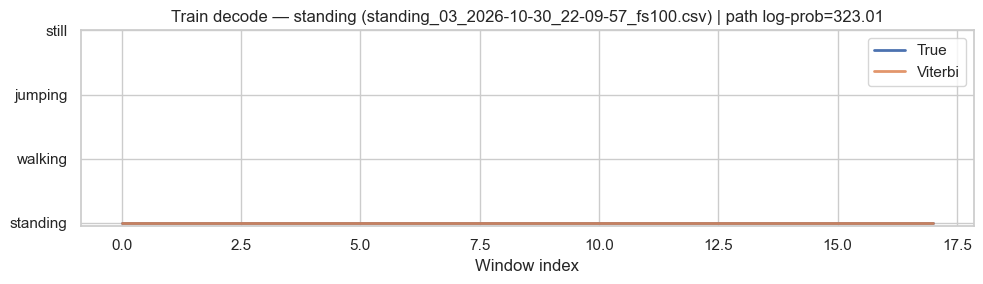

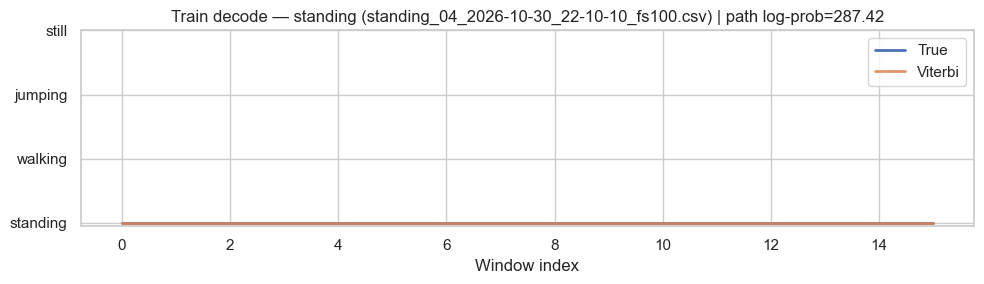

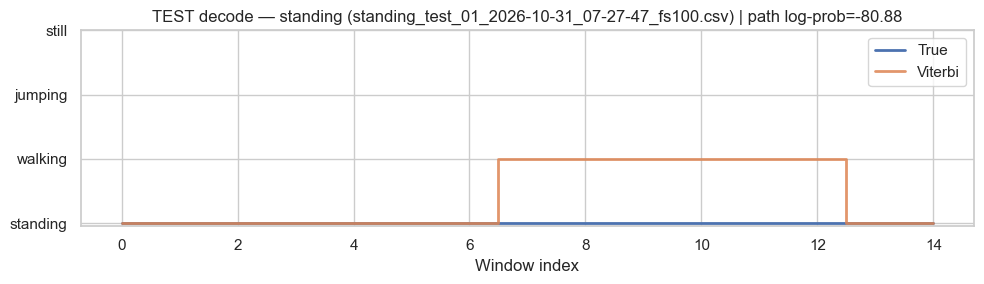

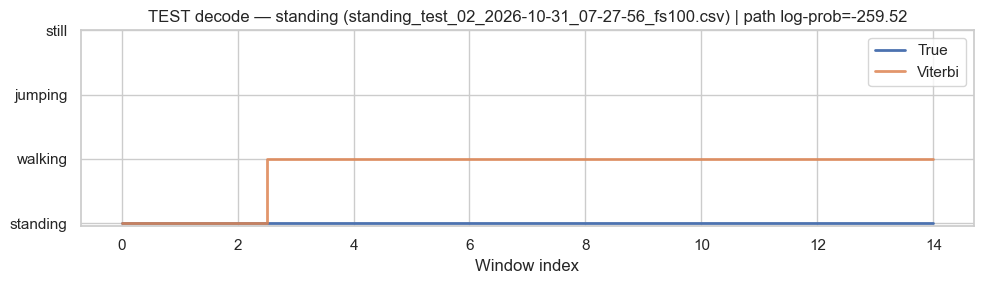

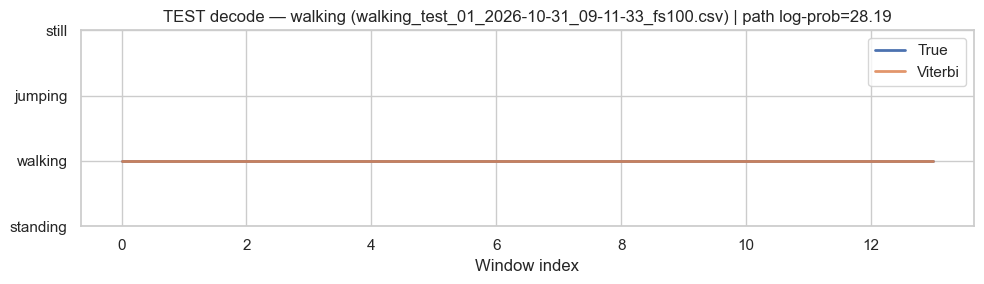

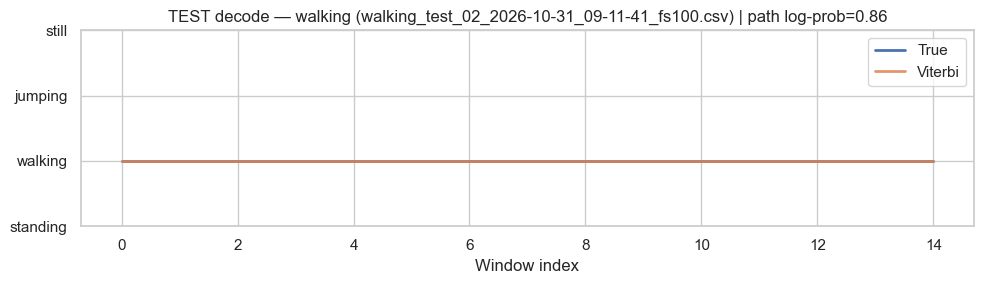

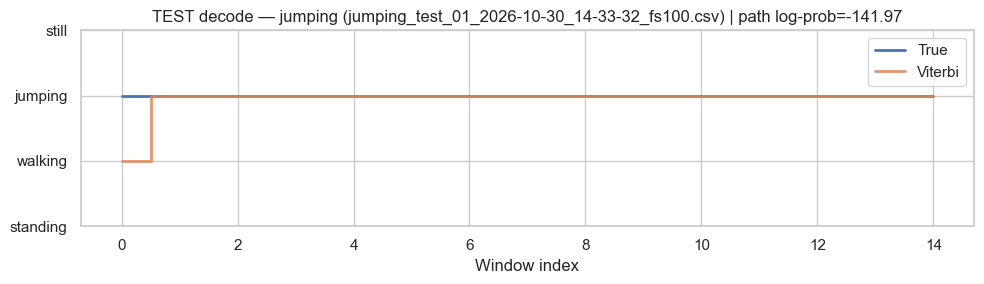

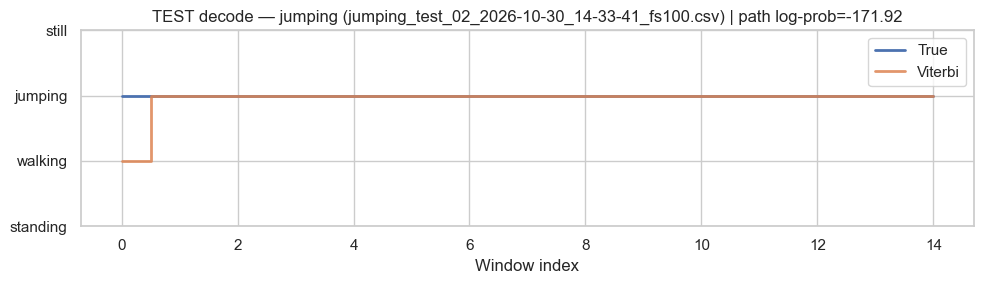

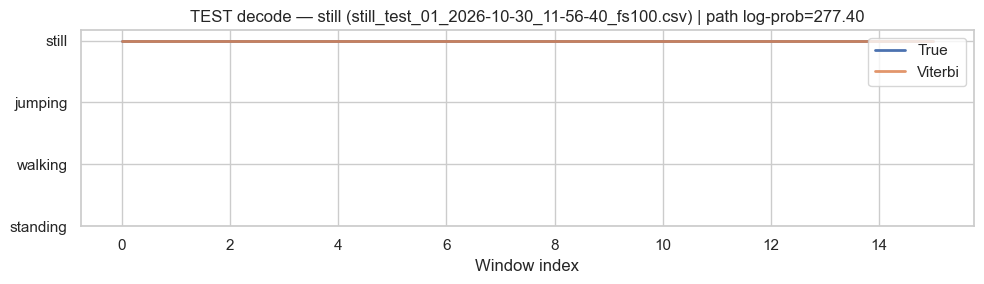

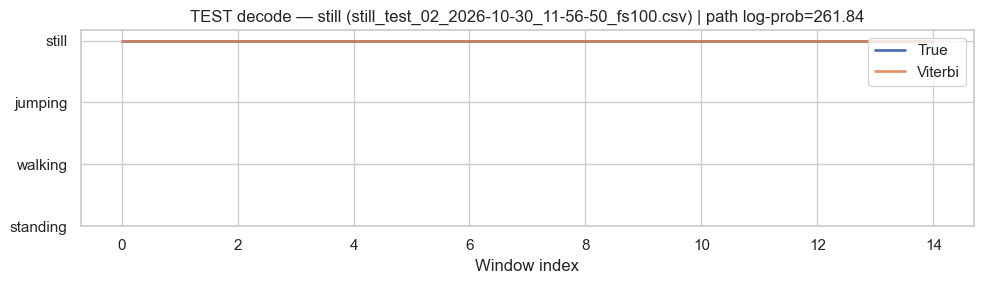

In [9]:
def plot_decoded(seq_X, seq_y, title):
    pred, logp = model.decode(seq_X)
    t = np.arange(len(pred))
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.step(t, seq_y, where="mid", label="True", lw=2)
    ax.step(t, pred, where="mid", label="Viterbi", lw=2, alpha=0.85)
    ax.set_yticks(range(4))
    ax.set_yticklabels(STATE_NAMES)
    ax.set_xlabel("Window index")
    ax.set_title(f"{title} | path log-prob={logp:.2f}")
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()
    return pred

# Show a few train files and all test files
for i in range(min(4, len(train_seqs))):
    act = STATE_NAMES[train_labs[i][0]]
    plot_decoded(train_seqs[i], train_labs[i], f"Train decode — {act} ({Path(train_meta[i]['file']).name})")

for i in range(len(test_seqs)):
    act = STATE_NAMES[test_labs[i][0]]
    plot_decoded(test_seqs[i], test_labs[i], f"TEST decode — {act} ({Path(test_meta[i]['file']).name})")

## 8. Unseen test files

`data/test/` has recordings I did not use while training (later sessions on the same phone). Metrics below are from those.

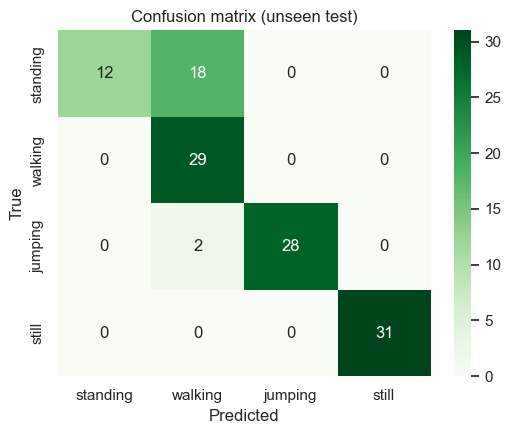

,State (Activity),Number of Samples,Sensitivity,Specificity,Overall Accuracy
0,standing,30,0.4000,1.0000,0.8333
1,walking,29,1.0000,0.7802,0.8333
2,jumping,30,0.9333,1.0000,0.8333
3,still,31,1.0000,1.0000,0.8333


Copy this table into Section 5 of the report.


In [10]:
y_true_list, y_pred_list = [], []
for seq_X, seq_y in zip(test_seqs, test_labs):
    pred = model.predict(seq_X)
    y_true_list.append(seq_y)
    y_pred_list.append(pred)

y_true = np.concatenate(y_true_list)
y_pred = np.concatenate(y_pred_list)

cm = confusion_matrix(y_true, y_pred, n_classes=4)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=STATE_NAMES,
    yticklabels=STATE_NAMES,
    ax=ax,
)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion matrix (unseen test)")
plt.tight_layout()
plt.show()

results_table = per_class_sensitivity_specificity(y_true, y_pred, 4, STATE_NAMES)
display(results_table)
print("Copy this table into Section 5 of the report.")

## 9. Why these algorithms for the metrics

Baum-Welch fits the parameters. Viterbi gives one discrete path per sequence, which is what I need for TP/FP style metrics and the confusion matrix. Soft Forward-Backward posteriors stay inside EM only.

## 10. Notes for the write-up

From my run: still/jumping were easy; standing often mixed with walking when the phone moved a little in my hand. A is very diagonal because each file is one activity. Resampling 100→50 Hz keeps windows consistent but can soften jump spikes a bit. Next time I would keep the phone placement more fixed.